# LIAR-Triage: run and analyse

**How to use:** keep this notebook in the same folder as `pipeline.py`, `.env` and `data/test.tsv`, then choose **Run All**.

- Part A runs the pipeline (sends claims to the model and saves the answers).
- Part B analyses the saved answers.

You only ever change the settings in **Step 1**.

---
# Part A: run the pipeline

## Step 0: check the setup
Installs anything missing into the Python this notebook uses, then checks that the files are in place.

In [1]:
%pip install -q openai python-dotenv pydantic pandas matplotlib

import sys
from pathlib import Path

print("Python used by this notebook:", sys.executable)
for f in ["pipeline.py", ".env", "data/test.tsv"]:
    print(("OK      " if Path(f).exists() else "MISSING ") + f)

Note: you may need to restart the kernel to use updated packages.
Python used by this notebook: C:\ProgramData\anaconda3\python.exe
OK      pipeline.py
OK      .env
OK      data/test.tsv



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 1: settings
- `PROVIDER`: `"groq"` now; `"gemini"` once you add a Gemini key to `.env`.
- `LIMIT`: how many claims to send. Use 50 while testing, then 1267 (the full test set).
- `RUN_PIPELINE`: set to `False` to skip Part A and only re-analyse saved results.

In [2]:
PROVIDER = "groq"
LIMIT = 50
WORKERS = 2
RUN_PIPELINE = True

## Step 2: run
Already-finished claims are skipped automatically, so running this again is safe and free.

In [3]:
import importlib
import pipeline
importlib.reload(pipeline)  # picks up any edits to pipeline.py

if RUN_PIPELINE:
    RESULTS = pipeline.run(provider=PROVIDER, limit=LIMIT, workers=WORKERS)
else:
    RESULTS = pipeline.results_path(PROVIDER)
print("Analysing:", RESULTS)

50 cached, 0 to process with openai/gpt-oss-20b
Done. Results in results\groq_openai-gpt-oss-20b.jsonl
Analysing: results\groq_openai-gpt-oss-20b.jsonl


---
# Part B: analyse

With 50 claims every number is a rough estimate: a smoke test, not a finding.

In [4]:
import json
import matplotlib.pyplot as plt
import pandas as pd

LABELS = ["pants-fire", "false", "barely-true", "half-true", "mostly-true", "true"]
pd.set_option("display.max_colwidth", 120)

## 1. Load results
A retried claim appears more than once in the file, so we keep only the **last** record per claim.

In [5]:
records = [json.loads(line) for line in Path(RESULTS).open(encoding="utf-8") if line.strip()]
df = pd.DataFrame(records).drop_duplicates("id", keep="last").reset_index(drop=True)
print(f"{len(records)} records in file -> {len(df)} unique claims")
df["status"].value_counts().to_frame("claims")

50 records in file -> 50 unique claims


,claims
status,
ok,45
invalid_json,5


## 2. Failure analysis
What did the model actually return when the output wasn't usable? Each pattern has a different fix.

In [6]:
failures = df[df["status"] != "ok"]
print(f"{len(failures)} failures\n")
for _, r in failures.iterrows():
    raw = r["raw"] or ""
    print(f"--- {r['id']}  [{r['status']}]  raw length = {len(raw)} chars")
    print("CLAIM:", r["statement"])
    print("RAW:  ", repr(raw[:400]) if raw else "(empty - the model returned no content)")
    if r.get("error"):
        print("ERROR:", str(r["error"])[:300])
    print()

5 failures

--- 9801.json  [invalid_json]  raw length = 0 chars
CLAIM: Before I was state treasurer, my Rhode Island business helped create over 1,000 jobs.
RAW:   (empty - the model returned no content)

--- 7780.json  [invalid_json]  raw length = 0 chars
CLAIM: Over the last several months, there was a review board headed by two distinguished Americans, Mike Mullen and Tom Pickering, who investigated every element of the Benghazi incident.
RAW:   (empty - the model returned no content)
ERROR: RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-20b` in organization `org_01m5nm1ahjeeqbf31rs3pay9g9` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Used 7202, Requested 1258. Please try again in 3.45s. Need more tokens? Upgrade

--- 1777.json  [invalid_json]  raw length = 0 chars
CLAIM: Ms. Kagan has spent her entire professional career in Harvard Square, Hyde Park and the D.C. Beltway.
RAW:   (empty - the model returned no

## 3. Flatten the valid outputs

In [7]:
ok = df[df["status"] == "ok"].copy()
out = pd.json_normalize(ok["output"].tolist())
ok = pd.concat([ok[["id", "gold_label", "statement", "latency_s"]].reset_index(drop=True), out], axis=1)
ok[["statement", "gold_label", "verdict", "confidence", "check_worthy", "topic"]].head(10)

,statement,gold_label,verdict,confidence,check_worthy,topic
0,Nearly 20% of our residents are born abroad.,true,false,0.95,True,demographics
1,A child born in America today will inherit $1.5 million in debt the moment theyre placed in their mothers arms.,mostly-true,false,0.95,True,debt
2,"If you and I fail to defund ObamaCare now, some 16,000 new IRS agents will be begin prying into our private medical ...",pants-fire,false,0.95,True,health care / privacy
3,America is No. 1 in wind power.,mostly-true,false,0.95,True,energy
4,"Says I am happy to decline PERS so that the County can save over $68,000 over a four year term that would have been ...",half-true,false,0.30,True,public finance
5,Says President Barack Obama spent nearly a trillion dollars on make-work government jobs.,false,false,0.95,True,politics
6,I am the only senator who turned down the state pension plan for part-time legislators.,true,false,0.30,True,politics
7,"He received ""A"" ratings from ""every conservative organization that gives ratings.""",mostly-true,false,0.90,True,politics
8,"The Hyde Amendmentlanguage was in the (human trafficking) bill. The Democratic sponsor admits it was in the bill, an...",mostly-true,false,0.90,True,law & policy
9,Say71 percent of doctors say Hillarys health concerns are serious and could be disqualifying.,false,false,0.20,True,health


## 4. Accuracy
- **6-class**: the exact PolitiFact rating (very hard).
- **Binary**: false-leaning (`pants-fire`, `false`, `barely-true`) vs true-leaning (the other three).
- **Macro-F1**: the F1 score averaged over classes, so always guessing the common label doesn't look good.
- **Baseline**: what you'd score by always guessing the most common label. The model has to beat this.

In [8]:
def per_class(y_true, y_pred, labels):
    rows = []
    for c in labels:
        tp = ((y_pred == c) & (y_true == c)).sum()
        fp = ((y_pred == c) & (y_true != c)).sum()
        fn = ((y_pred != c) & (y_true == c)).sum()
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * p * r / (p + r) if p + r else 0.0
        rows.append({"label": c, "precision": p, "recall": r, "f1": f1, "support": int((y_true == c).sum())})
    return pd.DataFrame(rows).set_index("label")

def macro_f1(y_true, y_pred, labels):
    present = [c for c in labels if (y_true == c).any() or (y_pred == c).any()]
    return per_class(y_true, y_pred, present)["f1"].mean()

FALSE_SIDE = {"pants-fire", "false", "barely-true"}
to_binary = lambda s: s.map(lambda v: "false-leaning" if v in FALSE_SIDE else "true-leaning")
BIN_LABELS = ["false-leaning", "true-leaning"]

y_true, y_pred = ok["gold_label"], ok["verdict"]
yb_true, yb_pred = to_binary(y_true), to_binary(y_pred)

summary = pd.DataFrame({
    "6-class": [(y_true == y_pred).mean(), macro_f1(y_true, y_pred, LABELS),
                y_true.value_counts(normalize=True).max()],
    "binary": [(yb_true == yb_pred).mean(), macro_f1(yb_true, yb_pred, BIN_LABELS),
               yb_true.value_counts(normalize=True).max()],
}, index=["accuracy", "macro-F1", "baseline accuracy (always guess most common)"]).round(3)
summary

,6-class,binary
accuracy,0.267,0.600
macro-F1,0.125,0.575
baseline accuracy (always guess most common),0.311,0.511


In [9]:
per_class(y_true, y_pred, LABELS).round(2)

,precision,recall,f1,support
label,,,,
pants-fire,0.00,0.00,0.00,2
false,0.30,0.71,0.43,14
barely-true,0.00,0.00,0.00,6
half-true,0.00,0.00,0.00,8
mostly-true,0.33,0.12,0.18,8
true,0.14,0.14,0.14,7


## 5. Confusion matrix
Rows are PolitiFact's truth; columns are the model's verdict. Numbers near the diagonal are "nearly right".

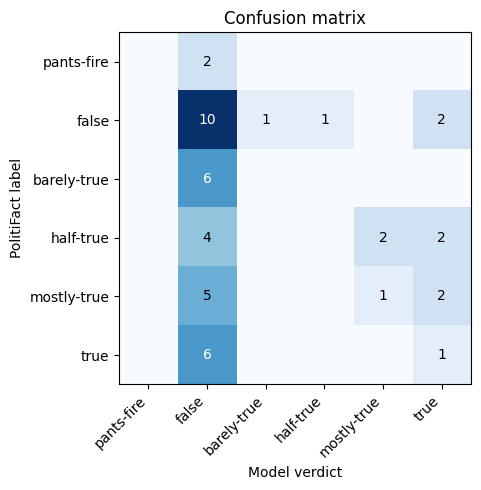

In [10]:
cm = pd.crosstab(y_true, y_pred).reindex(index=LABELS, columns=LABELS, fill_value=0)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm.values, cmap="Blues")
ax.set_xticks(range(6), LABELS, rotation=45, ha="right")
ax.set_yticks(range(6), LABELS)
ax.set_xlabel("Model verdict"); ax.set_ylabel("PolitiFact label")
for i in range(6):
    for j in range(6):
        v = cm.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.values.max() / 2 else "black")
ax.set_title("Confusion matrix")
plt.tight_layout(); plt.show()

## 6. Verdict bias
Does the model over-use some verdicts compared with PolitiFact?

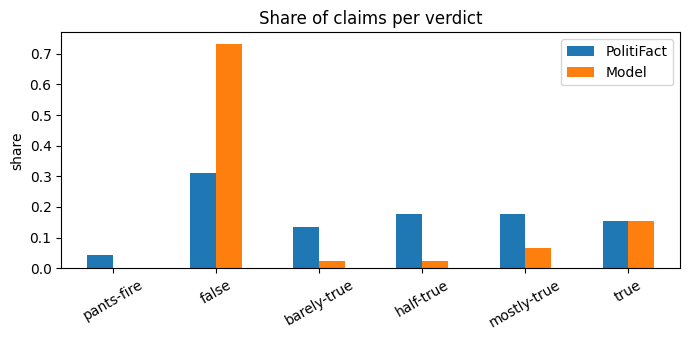

,PolitiFact,Model
pants-fire,0.04,0.00
false,0.31,0.73
barely-true,0.13,0.02
half-true,0.18,0.02
mostly-true,0.18,0.07
true,0.16,0.16


In [11]:
dist = pd.DataFrame({
    "PolitiFact": y_true.value_counts(normalize=True),
    "Model": y_pred.value_counts(normalize=True),
}).reindex(LABELS).fillna(0)
dist.plot.bar(figsize=(7, 3.5), rot=30, title="Share of claims per verdict")
plt.ylabel("share"); plt.tight_layout(); plt.show()
dist.round(2)

## 7. Calibration
When the model says 0.8 confidence, is it right about 80% of the time? (Using binary correctness.)

In [12]:
ok["correct_binary"] = (yb_true == yb_pred).values
ok["conf_bin"] = pd.cut(ok["confidence"], bins=[0, 0.5, 0.7, 0.85, 1.0], include_lowest=True)
ok.groupby("conf_bin", observed=True).agg(claims=("id", "count"),
                                          mean_confidence=("confidence", "mean"),
                                          accuracy=("correct_binary", "mean")).round(2)

,claims,mean_confidence,accuracy
conf_bin,,,
"(-0.001, 0.5]",4,0.25,0.50
"(0.5, 0.7]",5,0.70,0.60
"(0.7, 0.85]",4,0.81,0.75
"(0.85, 1.0]",32,0.93,0.59


## 8. Worst mistakes
Confident answers on the wrong side of the true/false line: the best examples for a write-up.

In [13]:
wrong = ok[~ok["correct_binary"]].sort_values("confidence", ascending=False)
wrong[["statement", "gold_label", "verdict", "confidence", "rationale"]].head(5)

,statement,gold_label,verdict,confidence,rationale
0,Nearly 20% of our residents are born abroad.,true,false,0.95,"U.S. Census and American Community Survey data show that roughly 12% of Austin’s residents were born abroad, well be..."
1,A child born in America today will inherit $1.5 million in debt the moment theyre placed in their mothers arms.,mostly-true,false,0.95,"In the United States, children do not inherit their parents’ debt; debts are paid from the parents’ assets or estate..."
3,America is No. 1 in wind power.,mostly-true,false,0.95,"China currently has the largest installed wind capacity, with the United States ranking second; therefore the claim ..."
13,Barack Obama has provided guns to Mexican drug cartels.,half-true,false,0.95,There is no credible evidence that President Obama ever supplied firearms to Mexican drug cartels; the claim is a kn...
40,"""The House has never failed to pass a budget in the modern era.""",true,false,0.95,The U.S. House of Representatives has failed to pass budget resolutions on multiple occasions in recent decades (e.g...


## 9. Notes for the write-up
- Failure patterns:
- Accuracy vs baseline:
- Bias:
- Calibration:
- Caveat: LIAR claims are from 2007-2016 and may be in the model's training data, so accuracy can reflect memorisation.